# Задание 1.
 По своему номеру варианта и таблице 1 определить номер набора данных и
требования к архитектуре сети:

Номер варианта 6

Номер набора данных 1 

Номер архитектуры сети 2

# Задание 2. 
По номеру набора входных данных выяснить из таблицы 2 его название. Так
как многие наборы данных имеются в библиотеках в готовом для обработки виде, желательно
сразу же проверить его наличие в используемой библиотеке. Списки готовых датасетов для
некоторых библиотек доступны по ссылкам

1 Caltech101: https://data.caltech.edu/records/20086

In [ ]:
import torch
from torch.utils.data import random_split
from torchvision import datasets, transforms

from torch.nn import (Module, Conv2d, Linear, MaxPool2d,
                      ReLU, LogSoftmax)

from torch import flatten 

import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from copy import deepcopy
from tqdm import tqdm
import numpy as np
import matplotlib.pyplot as plt
import math
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import accuracy_score
from typing import Dict, Any, Optional, List, Tuple

In [ ]:
#imagenet_data = torchvision.datasets.Caltech101(root = 'Сonvolutional networks/dataset', target_type = 'category', download = True)


HTTPError: HTTP Error 404: Not Found

Возникает ошибка HTTP Error 404: Not Found. Скачаем датасет с Kaggle (https://www.kaggle.com/datasets/imbikramsaha/caltech-101)

В качестве классов для классификации будем использовать 'bonsai' и 'joshua_tree'

In [12]:
# Объявляем трансформации, чтобы потом привести все изображения к формату 224x224 и 3 канальному выоходу
data_transform = transforms.Compose([
    transforms.Lambda(lambda img: img.convert('RGB')),
    transforms.Resize((224, 224)),
    transforms.ToTensor()
])

dataset = datasets.ImageFolder(
    root='dataset/',
    transform=data_transform
)

In [14]:
# train/test sizes
total_size = len(dataset)
test_size = int(0.2 * total_size)
train_size = total_size - test_size

# фиксируем сид для детерминированности
generator = torch.Generator().manual_seed(42)

train_dataset, test_dataset = random_split(dataset, [train_size, test_size], generator = generator)

In [16]:
print("Классы и их индексы:", dataset.class_to_idx)
print(f"Всего: {total_size} | Обучающая: {len(train_dataset)} | Тестовая: {len(test_dataset)}")

Классы и их индексы: {'bonsai': 0, 'joshua_tree': 1}
Всего: 192 | Обучающая: 154 | Тестовая: 38


# Задание 3
Определить требования к архитектуре сети из таблицы 3, после чего собрать
сеть, удовлятворяющую этим требованиям и способную обработать указанные данные. На
каждом свёрточном слое должно быть по 16 независимых ядер свёртки. Рассчитать, какое
количество параметров будет получаться на выходе сети. Можно использовать как примеры
следующие материалы:

Число свёрточных слоёв — 4, размер окна пулинга — 5 × 5

In [34]:
class MyConvNet(Module):
    def __init__(self, num_channels=3, num_classes=2, num_kernels = 16):
        super().__init__()
        # на каждом свёрточном слое по 16 ядер
        fc_hidden = 128

        # Блок 1: 224x224 -> 112x112
        self.conv1 = Conv2d(in_channels=num_channels, out_channels=num_kernels, kernel_size=(3, 3), padding=1)
        self.relu1 = ReLU()
        self.maxpool1 = MaxPool2d(kernel_size=(5, 5), stride=2, padding=2)

        # Блок 2: 112x112 -> 56x56
        self.conv2 = Conv2d(in_channels=num_kernels, out_channels=num_kernels, kernel_size=(3, 3), padding=1)
        self.relu2 = ReLU()
        self.maxpool2 = MaxPool2d(kernel_size=(5, 5), stride=2, padding=2)

        # Блок 3: 56x56 -> 28x28
        self.conv3 = Conv2d(in_channels=num_kernels, out_channels=num_kernels, kernel_size=(3, 3), padding=1)
        self.relu3 = ReLU()
        self.maxpool3 = MaxPool2d(kernel_size=(5, 5), stride=2, padding=2)

        # Блок 4: 28x28 -> 14x14
        self.conv4 = Conv2d(in_channels=num_kernels, out_channels=num_kernels, kernel_size=(3, 3), padding=1)
        self.relu4 = ReLU()
        self.maxpool4 = MaxPool2d(kernel_size=(5, 5), stride=2, padding=2)

        # Полносвязные слои: 16 каналов * 14 * 14 = 3136 входов
        self.fc1 = Linear(in_features=num_kernels * 14 * 14, out_features=fc_hidden)
        self.relu5 = ReLU()
        self.fc2 = Linear(in_features=fc_hidden, out_features=num_classes)
        self.logSoftmax = LogSoftmax(dim=1)

    def forward(self, x):
        x = self.maxpool1(self.relu1(self.conv1(x)))
        x = self.maxpool2(self.relu2(self.conv2(x)))
        x = self.maxpool3(self.relu3(self.conv3(x)))
        x = self.maxpool4(self.relu4(self.conv4(x)))

        x = flatten(x, 1)
        x = self.relu5(self.fc1(x))
        output = self.fc2(x)
        return output

# Задание 4.
Добавить к выходу свёрточной сети многослойный персептрон любой подходя-
щей структуры. Обучить сеть на указанных данных, получить итоговые характеристики точ-
ности классификации и график изменения ошибки на тестовой выборке.

In [20]:
class EarlyStopping():
  def __init__(
        self, 
        mode = 'min', 
        patience = 5, 
        threshold= 1e-4, 
        threshold_mode = 'rel'
    ):
    if mode not in {'min','max'}:
      raise ValueError(f"Available values for mode: max, min")
    if threshold_mode not in {'rel','abs'}:
      raise ValueError(f"Available values for threshold_mode: rel, abs")
    if not isinstance(patience, int):
      raise ValueError(f"Available values for patience must be int")
    if not isinstance(threshold, float):
      raise ValueError(f"Available values for threshold must be int and less than 1,0.")
    if threshold >= 1.0:
      raise ValueError(f"Available values for threshold must be int and less than 1,0.")

    self.mode = mode
    self.patience = patience
    self.threshold = threshold
    self.threshold_mode = threshold_mode
    self.count = 0
    self.best = None

  def changed_better(self, current, best):
    if self.mode == 'min' and self.threshold_mode == 'rel':
      return current < best - best * self.threshold
    elif self.mode == 'min' and self.threshold_mode == 'abs':
      return current < best - self.threshold

    elif self.mode =='max' and self.threshold_mode == 'rel':
      return current > best + best * self.threshold
    else:
      return current > best + self.threshold

  def __call__(self, tracked_parameter):
    current = float(tracked_parameter)
    if self.best is None:
      self.best = current
      return False

    if self.changed_better(current, self.best):
      self.best = current
      self.count = 0
    else:
      self.count += 1

    if self.count >= self.patience:
      self.count = 0
      return True

In [22]:
def train_one_model(
    model: nn.Module,
    train_loader: DataLoader,
    val_loader: DataLoader,
    lr: float = 1e-3,
    optimizer_name: str = 'Adam',
    scheduler_name: Optional[str] = 'ReduceLROnPlateau',
    weight_decay: float = 0.0,
    n_epochs: int = 50,
    early_stopping_patience: int = 5,
    loss_name: str = 'CrossEntropyLoss',
    device: str = 'cuda',
    verbose: bool = True
) -> Dict[str, Any]:
    '''
    train one model on one fold
    '''
    device = device if torch.cuda.is_available() else 'cpu'
    model.to(device)

    loss_model = getattr(nn, loss_name)()
    optimizer_cls = getattr(optim, optimizer_name)
    opt = optimizer_cls(model.parameters(), lr=lr, weight_decay=weight_decay)

    # Scheduler
    lr_scheduler = None
    if scheduler_name in ('Plateau', 'ReduceLROnPlateau'):
        lr_scheduler = optim.lr_scheduler.ReduceLROnPlateau(
            opt, mode='min', factor=0.1, patience=3
        )
    elif scheduler_name in ('Cosine', 'CosineAnnealingLR'):
        lr_scheduler = optim.lr_scheduler.CosineAnnealingLR(
            opt, T_max=n_epochs, eta_min=0.0
        )
    elif scheduler_name is not None:
        raise ValueError(f"Scheduler name: {scheduler_name} not in script")

    #EarlyStopping
    earlystopping = EarlyStopping(patience=early_stopping_patience)

    #Dict
    history = {
        'train_loss': [],
        'val_loss': [],
        'train_acc': [],
        'val_acc': [],
        'lr': []
    }
    best_val_loss = float('inf')
    best_val_acc = 0.0
    best_model_weights = deepcopy(model.state_dict())
    
    for epoch in range(n_epochs):
        # TRAINING 
        model.train()
        running_train_loss = []
        true_answer = 0

        train_loop = tqdm(train_loader, leave=False, disable=not verbose)
        for x, targets in train_loop:
            x, targets = x.to(device), targets.to(device)

            # Forward
            pred = model(x)
            loss = loss_model(pred, targets)

            # Backward
            opt.zero_grad()
            loss.backward()
            
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()

            #Compute metrics and loss
            running_train_loss.append(loss.item())
            mean_train_loss = np.mean(running_train_loss)

            #Max prob ind
            preds_cls = pred.argmax(dim=1)
            true_answer += (preds_cls == targets).sum().item()

            if verbose:
                train_loop.set_description(f"Epoch [{epoch+1}/{n_epochs}], train_loss = {mean_train_loss:.4f}")

        running_train_acc = true_answer / len(train_loader.dataset)
        history['train_loss'].append(mean_train_loss)
        history['train_acc'].append(running_train_acc)

        # VALIDATION 
        model.eval()
        val_true_answer = 0
        running_val_loss = []

        with torch.no_grad():
            for x, targets in val_loader:
                x, targets = x.to(device), targets.to(device)

                pred = model(x)
                loss = loss_model(pred, targets)

                running_val_loss.append(loss.item())
                preds_cls = pred.argmax(dim=1)
                val_true_answer += (preds_cls == targets).sum().item()

        mean_val_loss = np.mean(running_val_loss)
        running_val_acc = val_true_answer / len(val_loader.dataset)

        history['val_loss'].append(mean_val_loss)
        history['val_acc'].append(running_val_acc)

        # Scheduler step 
        if lr_scheduler is not None:
            if scheduler_name in ('Plateau', 'ReduceLROnPlateau'):
                lr_scheduler.step(mean_val_loss)
            else:
                lr_scheduler.step()

        current_lr = opt.param_groups[0]['lr']
        history['lr'].append(current_lr)

        if verbose:
            print(
                f"Epoch [{epoch+1}/{n_epochs}] | "
                f"train_loss: {mean_train_loss:.4f}, train_acc: {running_train_acc:.4f} | "
                f"val_loss: {mean_val_loss:.4f}, val_acc: {running_val_acc:.4f} | lr: {current_lr:.6f}"
            )

        # Saving best
        if mean_val_loss < best_val_loss:
            best_val_loss = mean_val_loss
            best_val_acc = running_val_acc
            best_model_weights = deepcopy(model.state_dict())

        # checking EarlyStopping
        if earlystopping(mean_val_loss):
            if verbose:
                print(f"Early stopping worked on {epoch+1}")
            break

    # loading best weights
    model.load_state_dict(best_model_weights)

    return {
        'model': model,
        'best_val_loss': best_val_loss,
        'best_val_acc': best_val_acc,
        'epochs_trained': epoch + 1,
        'history': history
    }

In [25]:
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

In [26]:
model = MyConvNet(num_channels=3, num_classes=2)
results = train_one_model(
    model=model,
    train_loader=train_loader,
    val_loader=test_loader,
)

Epoch [1/50] | train_loss: 0.7056, train_acc: 0.6039 | val_loss: 0.7694, val_acc: 0.6053 | lr: 0.001000


Epoch [2/50] | train_loss: 0.6425, train_acc: 0.6818 | val_loss: 0.6583, val_acc: 0.6053 | lr: 0.001000


Epoch [3/50] | train_loss: 0.6270, train_acc: 0.6818 | val_loss: 0.6561, val_acc: 0.6053 | lr: 0.001000


Epoch [4/50] | train_loss: 0.6348, train_acc: 0.6818 | val_loss: 0.6690, val_acc: 0.6053 | lr: 0.001000


Epoch [5/50] | train_loss: 0.6195, train_acc: 0.6818 | val_loss: 0.6650, val_acc: 0.6053 | lr: 0.001000


Epoch [6/50] | train_loss: 0.6048, train_acc: 0.6818 | val_loss: 0.6457, val_acc: 0.6053 | lr: 0.001000


... (19 outputs left out)

Epoch [26/50] | train_loss: 0.0800, train_acc: 0.9805 | val_loss: 0.3876, val_acc: 0.8421 | lr: 0.000100


Epoch [27/50] | train_loss: 0.0744, train_acc: 0.9870 | val_loss: 0.3743, val_acc: 0.8421 | lr: 0.000100


Epoch [28/50] | train_loss: 0.0716, train_acc: 0.9740 | val_loss: 0.3438, val_acc: 0.8684 | lr: 0.000010


Epoch [29/50] | train_loss: 0.0658, train_acc: 0.9740 | val_loss: 0.3431, val_acc: 0.8684 | lr: 0.000010
Early stopping worked on 29


In [27]:
print(f"\nИтоговая лучшая точность на тестовой выборке: {results['best_val_acc'] * 100:.2f}%")
print(f"Минимальная ошибка на тестовой выборке: {results['best_val_loss']:.4f}")


Итоговая лучшая точность на тестовой выборке: 89.47%
Минимальная ошибка на тестовой выборке: 0.2727


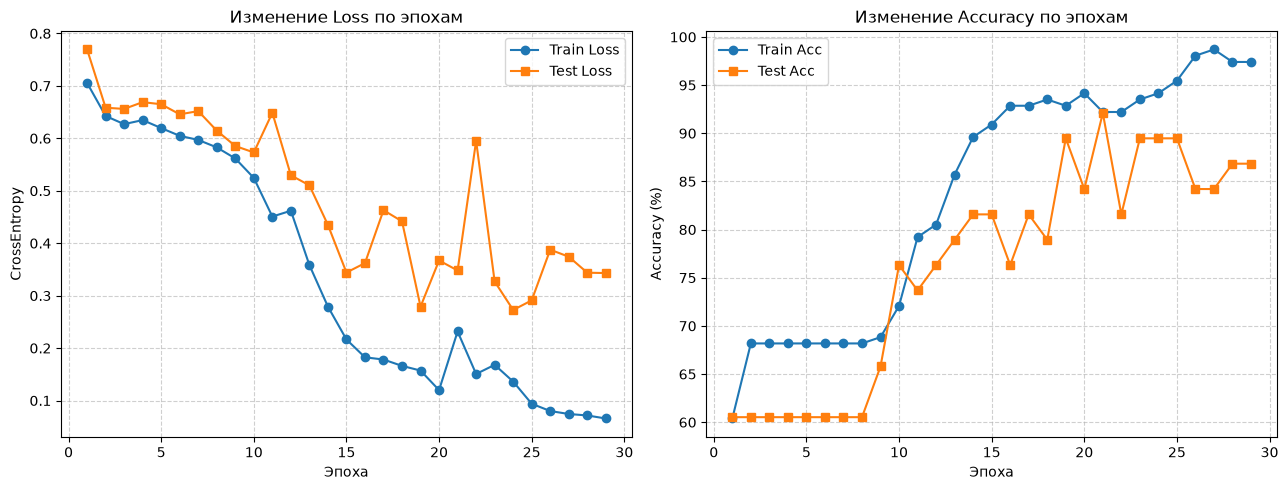

In [29]:
history = results['history']
epochs_range = range(1, len(history['train_loss']) + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# Loss
ax1.plot(epochs_range, history['train_loss'], label='Train Loss', marker='o')
ax1.plot(epochs_range, history['val_loss'], label='Test Loss', marker='s')
ax1.set_title('Изменение Loss по эпохам')
ax1.set_xlabel('Эпоха')
ax1.set_ylabel('CrossEntropy')
ax1.grid(True, linestyle='--', alpha=0.6)
ax1.legend()

# Acc
ax2.plot(epochs_range, [a * 100 for a in history['train_acc']], label='Train Acc', marker='o')
ax2.plot(epochs_range, [a * 100 for a in history['val_acc']], label='Test Acc', marker='s')
ax2.set_title('Изменение Accuracy по эпохам')
ax2.set_xlabel('Эпоха')
ax2.set_ylabel('Accuracy (%)')
ax2.grid(True, linestyle='--', alpha=0.6)
ax2.legend()

plt.tight_layout()
plt.show()

Расчет метрик и матрица ошибок

Classification Report:

              precision    recall  f1-score   support

      bonsai     0.9130    0.9130    0.9130        23
 joshua_tree     0.8667    0.8667    0.8667        15

    accuracy                         0.8947        38
   macro avg     0.8899    0.8899    0.8899        38
weighted avg     0.8947    0.8947    0.8947        38



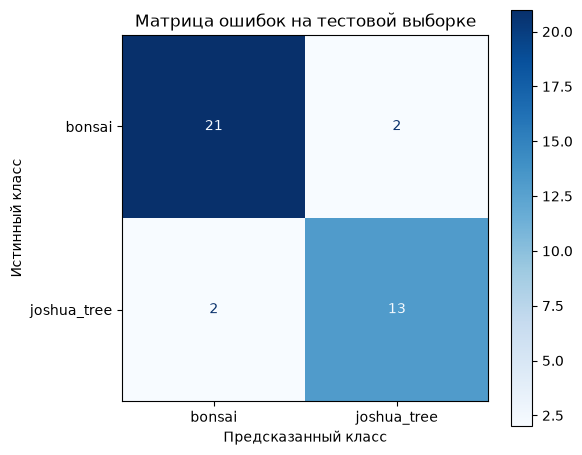

In [31]:
# Берём лучшую модель из результатов обучения
trained_model = results['model']
device = next(trained_model.parameters()).device
trained_model.eval()

all_preds = []
all_targets = []

# Собираем предсказания на всей тестовой выборке
with torch.no_grad():
    for x, targets in test_loader:
        x = x.to(device)
        outputs = trained_model(x)
        preds = outputs.argmax(dim=1) 

        all_preds.extend(preds.cpu().numpy())
        all_targets.extend(targets.numpy())

# Имена классов
class_names = dataset.classes  # ['bonsai', 'joshua_tree']

# Precision, Recall, F1-score и Accuracy
print("Classification Report:\n")
print(classification_report(all_targets, all_preds, target_names=class_names, digits=4))

# Confusion Matrix
cm = confusion_matrix(all_targets, all_preds)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)

fig, ax = plt.subplots(figsize=(6, 5))
disp.plot(cmap='Blues', ax=ax, values_format='d')
ax.set_title('Матрица ошибок на тестовой выборке')
ax.set_xlabel('Предсказанный класс')
ax.set_ylabel('Истинный класс')
plt.tight_layout()
plt.show()

Выведем из test_loader изображения, на которых обученная модель сделала неверное предсказание

Всего ошибок на тестовой выборке: 4 из 38


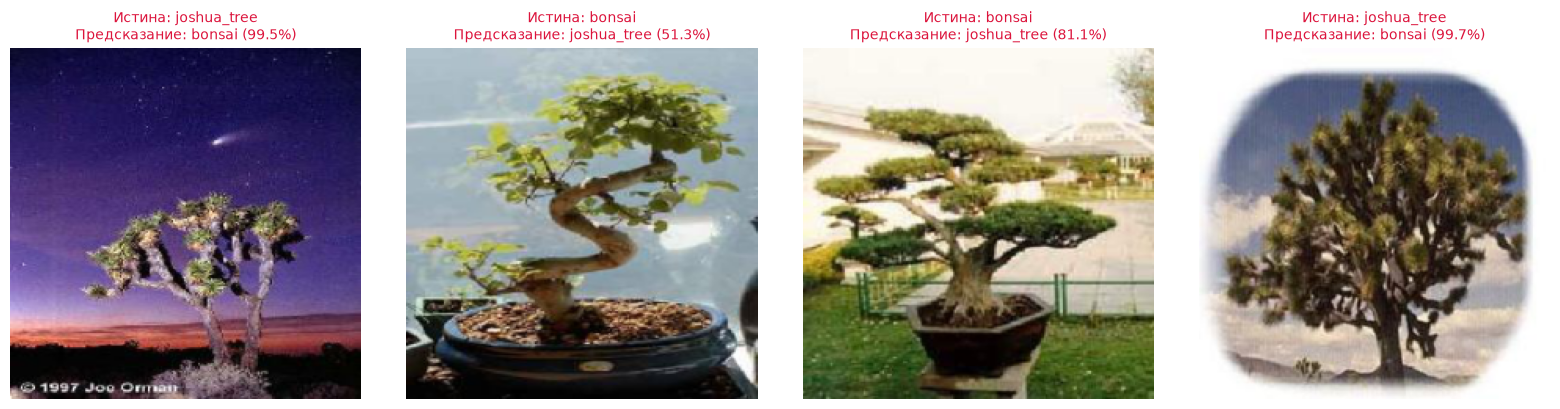

In [ ]:
trained_model = results['model']
device = next(trained_model.parameters()).device
trained_model.eval()

class_names = dataset.classes  # ['bonsai', 'joshua_tree']
misclassified = []

# Собираем все изображения, на которых модель ошиблась
with torch.no_grad():
    for x, targets in test_loader:
        x_dev = x.to(device)
        outputs = trained_model(x_dev)
        
        # Считаем вероятности и предсказанные классы
        probs = torch.softmax(outputs, dim=1)
        preds = outputs.argmax(dim=1).cpu()

        # Находим индексы неверных предсказаний в текущем батче
        wrong_mask = preds != targets
        for i in torch.where(wrong_mask)[0]:
            img_tensor = x[i]
            true_label = targets[i].item()
            pred_label = preds[i].item()
            confidence = probs[i, pred_label].item()
            misclassified.append((img_tensor, true_label, pred_label, confidence))

print(f"Всего ошибок на тестовой выборке: {len(misclassified)} из {len(test_loader.dataset)}")

#Отрисовываем найденные ошибки
if len(misclassified) == 0:
    print("Модель не допустила ни одной ошибки на тестовой выборке")
else:
    cols = min(4, len(misclassified))
    rows = math.ceil(len(misclassified) / cols)

    fig, axes = plt.subplots(rows, cols, figsize=(4 * cols, 4 * rows))

    axes = [axes] if len(misclassified) == 1 else axes.flatten()

    for idx, (img_tensor, true_lbl, pred_lbl, conf) in enumerate(misclassified):
        # Переводим тензор [C, H, W] -> [H, W, C] и обрезаем значения в [0, 1]
        img = img_tensor.permute(1, 2, 0).numpy().clip(0, 1)

        axes[idx].imshow(img)
        axes[idx].set_title(
            f"Истина: {class_names[true_lbl]}\n"
            f"Предсказание: {class_names[pred_lbl]} ({conf * 100:.1f}%)",
            color='crimson',
            fontsize=10
        )
        axes[idx].axis('off')

    # Скрываем пустые ячейки сетки, если они остались
    for idx in range(len(misclassified), len(axes)):
        axes[idx].axis('off')

    plt.tight_layout()
    plt.show()

# Задание 5.
Оценить воздействие на результат изменения количества ядер свёртки до 8,
32, 64 на каждом слое: повышается ли достигаемая точность, быстрее ли обучается модель
(по количеству эпох обучения и по затратам времени)?

16 ядер - 

Итоговая лучшая точность на тестовой выборке: 89.47%

Минимальная ошибка на тестовой выборке: 0.2727

Количество эпох: 29

Затраченное время: 304 секунды

## 8 ядер

In [35]:
model = MyConvNet(num_channels=3, num_classes=2, num_kernels = 8)
results = train_one_model(
    model=model,
    train_loader=train_loader,
    val_loader=test_loader,
)

Epoch [1/50] | train_loss: 0.6358, train_acc: 0.6818 | val_loss: 0.7001, val_acc: 0.6053 | lr: 0.001000


Epoch [2/50] | train_loss: 0.6311, train_acc: 0.6818 | val_loss: 0.6626, val_acc: 0.6053 | lr: 0.001000


Epoch [3/50] | train_loss: 0.6259, train_acc: 0.6818 | val_loss: 0.6563, val_acc: 0.6053 | lr: 0.001000


Epoch [4/50] | train_loss: 0.6292, train_acc: 0.6818 | val_loss: 0.6597, val_acc: 0.6053 | lr: 0.001000


Epoch [5/50] | train_loss: 0.6264, train_acc: 0.6818 | val_loss: 0.6684, val_acc: 0.6053 | lr: 0.001000


Epoch [6/50] | train_loss: 0.6181, train_acc: 0.6818 | val_loss: 0.6486, val_acc: 0.6053 | lr: 0.001000


... (12 outputs left out)

Epoch [19/50] | train_loss: 0.2255, train_acc: 0.9091 | val_loss: 0.3546, val_acc: 0.9211 | lr: 0.001000


Epoch [20/50] | train_loss: 0.2156, train_acc: 0.9221 | val_loss: 0.2742, val_acc: 0.8947 | lr: 0.001000


Epoch [21/50] | train_loss: 0.1864, train_acc: 0.9156 | val_loss: 0.3014, val_acc: 0.8684 | lr: 0.000100


Epoch [22/50] | train_loss: 0.1756, train_acc: 0.9286 | val_loss: 0.2801, val_acc: 0.8947 | lr: 0.000100
Early stopping worked on 22


In [37]:
print(f"\nИтоговая лучшая точность на тестовой выборке: {results['best_val_acc'] * 100:.2f}%")
print(f"Минимальная ошибка на тестовой выборке: {results['best_val_loss']:.4f}")
print(f"Количество эпох: {results['epochs_trained'] }")



Итоговая лучшая точность на тестовой выборке: 92.11%
Минимальная ошибка на тестовой выборке: 0.2529
Количество эпох: 22


8 ядер:
Итоговая лучшая точность на тестовой выборке: 92.11%

Минимальная ошибка на тестовой выборке: 0.2529

Количество эпох: 22

Время: 264 секунды

In [ ]:
model = MyConvNet(num_channels=3, num_classes=2, num_kernels = 32)
results = train_one_model(
    model=model,
    train_loader=train_loader,
    val_loader=test_loader,
)
print(f"\nИтоговая лучшая точность на тестовой выборке: {results['best_val_acc'] * 100:.2f}%")
print(f"Минимальная ошибка на тестовой выборке: {results['best_val_loss']:.4f}")
print(f"Количество эпох: {results['epochs_trained'] }")

Epoch [1/50] | train_loss: 0.6453, train_acc: 0.6818 | val_loss: 0.6540, val_acc: 0.6053 | lr: 0.001000


Epoch [2/50] | train_loss: 0.6412, train_acc: 0.6818 | val_loss: 0.6947, val_acc: 0.6053 | lr: 0.001000


Epoch [3/50] | train_loss: 0.6302, train_acc: 0.6818 | val_loss: 0.6456, val_acc: 0.6053 | lr: 0.001000


Epoch [4/50] | train_loss: 0.6018, train_acc: 0.6818 | val_loss: 0.6371, val_acc: 0.6053 | lr: 0.001000


Epoch [5/50] | train_loss: 0.5781, train_acc: 0.6818 | val_loss: 0.5936, val_acc: 0.6053 | lr: 0.001000


Epoch [6/50] | train_loss: 0.5386, train_acc: 0.6818 | val_loss: 0.5476, val_acc: 0.6053 | lr: 0.001000


... (2 outputs left out)

Epoch [9/50] | train_loss: 0.2900, train_acc: 0.9221 | val_loss: 0.7613, val_acc: 0.8421 | lr: 0.001000


Epoch [10/50] | train_loss: 0.3652, train_acc: 0.9026 | val_loss: 0.7192, val_acc: 0.8684 | lr: 0.001000


Epoch [11/50] | train_loss: 0.3222, train_acc: 0.8961 | val_loss: 0.4356, val_acc: 0.9211 | lr: 0.000100


Epoch [12/50] | train_loss: 0.2211, train_acc: 0.9221 | val_loss: 0.4238, val_acc: 0.9211 | lr: 0.000100
Early stopping worked on 12

Итоговая лучшая точность на тестовой выборке: 89.47%

Минимальная ошибка на тестовой выборке: 0.4155
Количество эпох: 12


32 ядра:

Итоговая лучшая точность на тестовой выборке: 89.47%

Минимальная ошибка на тестовой выборке: 0.4155

Количество эпох: 12

Время: 9 секунд

In [39]:
model = MyConvNet(num_channels=3, num_classes=2, num_kernels = 64)
results = train_one_model(
    model=model,
    train_loader=train_loader,
    val_loader=test_loader,
)
print(f"\nИтоговая лучшая точность на тестовой выборке: {results['best_val_acc'] * 100:.2f}%")
print(f"Минимальная ошибка на тестовой выборке: {results['best_val_loss']:.4f}")
print(f"Количество эпох: {results['epochs_trained'] }")

Epoch [1/50] | train_loss: 0.6684, train_acc: 0.5779 | val_loss: 0.6854, val_acc: 0.6053 | lr: 0.001000


Epoch [2/50] | train_loss: 0.6046, train_acc: 0.6818 | val_loss: 0.6368, val_acc: 0.6053 | lr: 0.001000


Epoch [3/50] | train_loss: 0.6788, train_acc: 0.6818 | val_loss: 0.7214, val_acc: 0.6053 | lr: 0.001000


Epoch [4/50] | train_loss: 0.5534, train_acc: 0.7403 | val_loss: 0.5286, val_acc: 0.6842 | lr: 0.001000


Epoch [5/50] | train_loss: 0.4984, train_acc: 0.7468 | val_loss: 0.5234, val_acc: 0.7895 | lr: 0.001000


Epoch [6/50] | train_loss: 0.3913, train_acc: 0.8442 | val_loss: 0.3285, val_acc: 0.8684 | lr: 0.001000


... (12 outputs left out)

Epoch [19/50] | train_loss: 0.0206, train_acc: 0.9935 | val_loss: 0.1044, val_acc: 0.9211 | lr: 0.001000


Epoch [20/50] | train_loss: 0.0142, train_acc: 0.9935 | val_loss: 0.0940, val_acc: 0.9474 | lr: 0.001000


Epoch [21/50] | train_loss: 0.0266, train_acc: 0.9935 | val_loss: 0.1806, val_acc: 0.9211 | lr: 0.000100


Epoch [22/50] | train_loss: 0.0230, train_acc: 0.9870 | val_loss: 0.1946, val_acc: 0.9211 | lr: 0.000100
Early stopping worked on 22

Итоговая лучшая точность на тестовой выборке: 97.37%
Минимальная ошибка на тестовой выборке: 0.0324
Количество эпох: 22


64 ядра:

Итоговая лучшая точность на тестовой выборке: 97.37%

Минимальная ошибка на тестовой выборке: 0.0324

Количество эпох: 22

Время: 23 секунды

Получился лучший результат из всех. Исследуем его подробнее

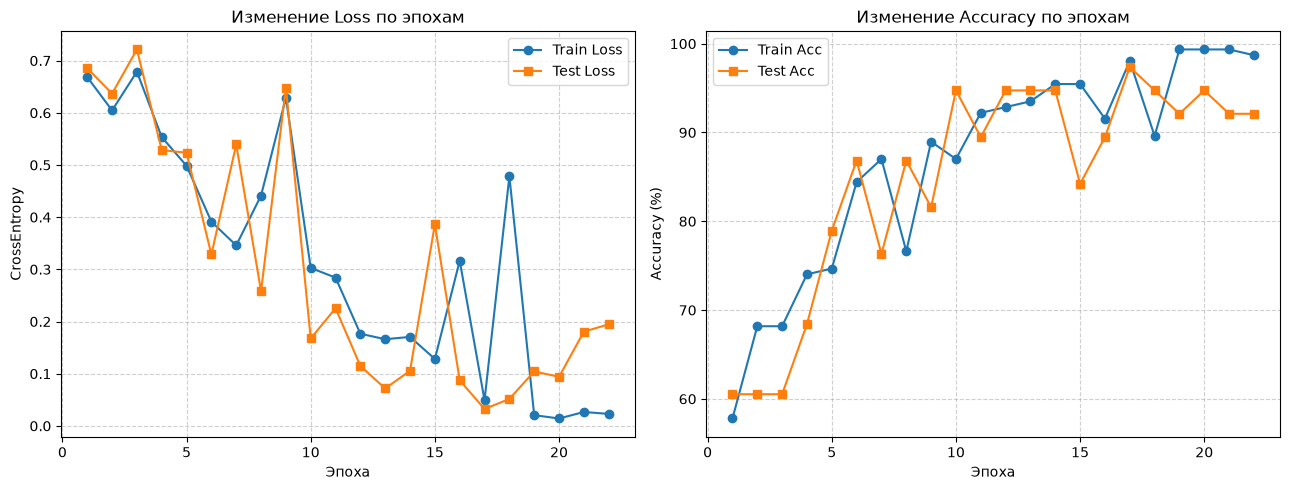

Classification Report:

              precision    recall  f1-score   support

      bonsai     0.9583    1.0000    0.9787        23
 joshua_tree     1.0000    0.9333    0.9655        15

    accuracy                         0.9737        38
   macro avg     0.9792    0.9667    0.9721        38
weighted avg     0.9748    0.9737    0.9735        38



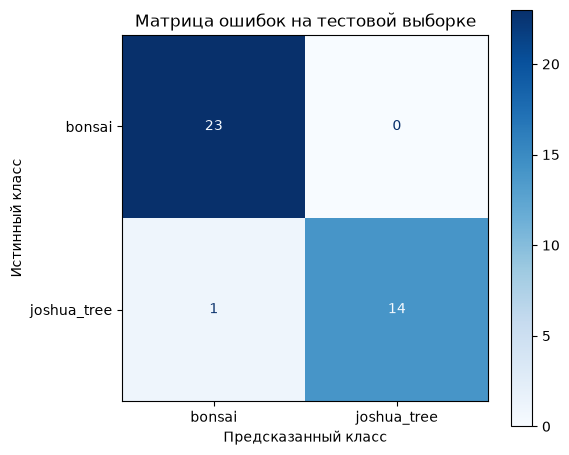

Всего ошибок на тестовой выборке: 1 из 38


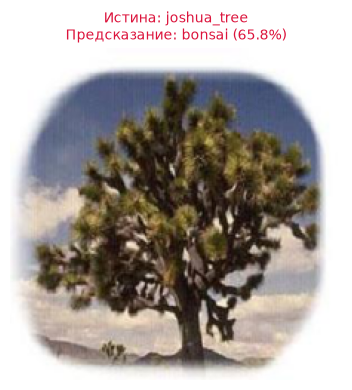

In [41]:
history = results['history']
epochs_range = range(1, len(history['train_loss']) + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# Loss
ax1.plot(epochs_range, history['train_loss'], label='Train Loss', marker='o')
ax1.plot(epochs_range, history['val_loss'], label='Test Loss', marker='s')
ax1.set_title('Изменение Loss по эпохам')
ax1.set_xlabel('Эпоха')
ax1.set_ylabel('CrossEntropy')
ax1.grid(True, linestyle='--', alpha=0.6)
ax1.legend()

# Acc
ax2.plot(epochs_range, [a * 100 for a in history['train_acc']], label='Train Acc', marker='o')
ax2.plot(epochs_range, [a * 100 for a in history['val_acc']], label='Test Acc', marker='s')
ax2.set_title('Изменение Accuracy по эпохам')
ax2.set_xlabel('Эпоха')
ax2.set_ylabel('Accuracy (%)')
ax2.grid(True, linestyle='--', alpha=0.6)
ax2.legend()

plt.tight_layout()
plt.show()

# Берём лучшую модель из результатов обучения
trained_model = results['model']
device = next(trained_model.parameters()).device
trained_model.eval()

all_preds = []
all_targets = []

# Собираем предсказания на всей тестовой выборке
with torch.no_grad():
    for x, targets in test_loader:
        x = x.to(device)
        outputs = trained_model(x)
        preds = outputs.argmax(dim=1) 

        all_preds.extend(preds.cpu().numpy())
        all_targets.extend(targets.numpy())

# Имена классов
class_names = dataset.classes  # ['bonsai', 'joshua_tree']

# Precision, Recall, F1-score и Accuracy
print("Classification Report:\n")
print(classification_report(all_targets, all_preds, target_names=class_names, digits=4))

# Confusion Matrix
cm = confusion_matrix(all_targets, all_preds)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)

fig, ax = plt.subplots(figsize=(6, 5))
disp.plot(cmap='Blues', ax=ax, values_format='d')
ax.set_title('Матрица ошибок на тестовой выборке')
ax.set_xlabel('Предсказанный класс')
ax.set_ylabel('Истинный класс')
plt.tight_layout()
plt.show()

trained_model = results['model']
device = next(trained_model.parameters()).device
trained_model.eval()

class_names = dataset.classes  # ['bonsai', 'joshua_tree']
misclassified = []

# Собираем все изображения, на которых модель ошиблась
with torch.no_grad():
    for x, targets in test_loader:
        x_dev = x.to(device)
        outputs = trained_model(x_dev)
        
        # Считаем вероятности и предсказанные классы
        probs = torch.softmax(outputs, dim=1)
        preds = outputs.argmax(dim=1).cpu()

        # Находим индексы неверных предсказаний в текущем батче
        wrong_mask = preds != targets
        for i in torch.where(wrong_mask)[0]:
            img_tensor = x[i]
            true_label = targets[i].item()
            pred_label = preds[i].item()
            confidence = probs[i, pred_label].item()
            misclassified.append((img_tensor, true_label, pred_label, confidence))

print(f"Всего ошибок на тестовой выборке: {len(misclassified)} из {len(test_loader.dataset)}")

#Отрисовываем найденные ошибки
if len(misclassified) == 0:
    print("Модель не допустила ни одной ошибки на тестовой выборке")
else:
    cols = min(4, len(misclassified))
    rows = math.ceil(len(misclassified) / cols)

    fig, axes = plt.subplots(rows, cols, figsize=(4 * cols, 4 * rows))

    axes = [axes] if len(misclassified) == 1 else axes.flatten()

    for idx, (img_tensor, true_lbl, pred_lbl, conf) in enumerate(misclassified):
        # Переводим тензор [C, H, W] -> [H, W, C] и обрезаем значения в [0, 1]
        img = img_tensor.permute(1, 2, 0).numpy().clip(0, 1)

        axes[idx].imshow(img)
        axes[idx].set_title(
            f"Истина: {class_names[true_lbl]}\n"
            f"Предсказание: {class_names[pred_lbl]} ({conf * 100:.1f}%)",
            color='crimson',
            fontsize=10
        )
        axes[idx].axis('off')

    # Скрываем пустые ячейки сетки, если они остались
    for idx in range(len(misclassified), len(axes)):
        axes[idx].axis('off')

    plt.tight_layout()
    plt.show()

получилось, что при 64 ядрах - самое быстрое и самое эффективное по метрике. Допускается всего 1 ошибка на тесте.
При увелечении ядер - увеличивается число степеней свободы и выше шанс, что при случайной инициализации часть ядер окажется удачно настроена, поэтому град спуск быстрее находит минимум, ошибка падает за меньшее число эпох и раньше срабатывает ерли стапинг. И поскольку их больше, то на большее число каналов посылаются признаки, и чем их больше - тем сложнее зависимость может уловиться при меньшем количестве данных.

# Задание 6.
 Превратить свёрточную сеть в остаточную, добавив через каждый два слоя сум-
мирование их выходов со входом и повторив обучение. Повышается ли достигаемая точность,

быстрее ли обучается модель (по количеству эпох обучения и по затратам времени)?

In [42]:
class MyResNet(Module):
    def __init__(self, num_channels=3, num_classes=2, num_kernels = 64):
        super().__init__()
        fc_hidden = 128

        # Блок 1: 224x224 -> 112x112
        self.conv1 = Conv2d(in_channels=num_channels, out_channels=num_kernels, kernel_size=(3, 3), padding=1)
        self.relu1 = ReLU()
        self.maxpool1 = MaxPool2d(kernel_size=(5, 5), stride=2, padding=2)

        # Блок 2: 112x112 -> 56x56
        self.conv2 = Conv2d(in_channels=num_kernels, out_channels=num_kernels, kernel_size=(3, 3), padding=1)
        self.relu2 = ReLU()
        self.maxpool2 = MaxPool2d(kernel_size=(5, 5), stride=2, padding=2)

        # Проекция для skip-connection 1: меняет каналы (3 -> num_kernels) и сжимает в 4 раза (stride=4)
        self.shortcut1 = Conv2d(num_channels, num_kernels, kernel_size=1, stride=4)

        # Блок 3: 56x56 -> 28x28
        self.conv3 = Conv2d(in_channels=num_kernels, out_channels=num_kernels, kernel_size=(3, 3), padding=1)
        self.relu3 = ReLU()
        self.maxpool3 = MaxPool2d(kernel_size=(5, 5), stride=2, padding=2)

        # Блок 4: 28x28 -> 14x14
        self.conv4 = Conv2d(in_channels=num_kernels, out_channels=num_kernels, kernel_size=(3, 3), padding=1)
        self.relu4 = ReLU()
        self.maxpool4 = MaxPool2d(kernel_size=(5, 5), stride=2, padding=2)

        # Проекция для skip-connection 2: каналы совпадают, только сжимаем в 4 раза (stride=4)
        self.shortcut2 = Conv2d(num_kernels, num_kernels, kernel_size=1, stride=4)

        # Полносвязные слои: 16 каналов * 14 * 14 = 3136 входов
        self.fc1 = Linear(in_features=num_kernels * 14 * 14, out_features=fc_hidden)
        self.relu5 = ReLU()
        self.fc2 = Linear(in_features=fc_hidden, out_features=num_classes)
        self.logSoftmax = LogSoftmax(dim=1)

    def forward(self, x):
        # Первый остаточный блок
        identity1 = self.shortcut1(x)
        out = self.maxpool1(self.relu1(self.conv1(x)))
        out = self.maxpool2(self.conv2(out))
        out = self.relu2(out + identity1)  # суммируем выход 2-го слоя со входом блока

        # Второй остаточный блок
        identity2 = self.shortcut2(out)
        out = self.maxpool3(self.relu3(self.conv3(out)))
        out = self.maxpool4(self.conv4(out))
        out = self.relu4(out + identity2)  # суммируем выход 4-го слоя со входом блока

        # Классификатор
        out = flatten(out, 1)
        out = self.relu5(self.fc1(out))
        output = self.fc2(out)
        return output

In [43]:
model = MyResNet(num_channels=3, num_classes=2, num_kernels = 64)
results = train_one_model(
    model=model,
    train_loader=train_loader,
    val_loader=test_loader,
)

Epoch [1/50] | train_loss: 0.8924, train_acc: 0.5390 | val_loss: 0.6391, val_acc: 0.6053 | lr: 0.001000


Epoch [2/50] | train_loss: 0.5964, train_acc: 0.6818 | val_loss: 0.5964, val_acc: 0.6053 | lr: 0.001000


Epoch [3/50] | train_loss: 0.4783, train_acc: 0.7468 | val_loss: 0.4597, val_acc: 0.7105 | lr: 0.001000


Epoch [4/50] | train_loss: 0.3657, train_acc: 0.8571 | val_loss: 0.3968, val_acc: 0.8684 | lr: 0.001000


Epoch [5/50] | train_loss: 0.2748, train_acc: 0.9221 | val_loss: 0.4807, val_acc: 0.8158 | lr: 0.001000


Epoch [6/50] | train_loss: 0.3019, train_acc: 0.8831 | val_loss: 0.3911, val_acc: 0.8684 | lr: 0.001000


... (10 outputs left out)

Epoch [17/50] | train_loss: 0.0343, train_acc: 0.9870 | val_loss: 0.1945, val_acc: 0.9474 | lr: 0.001000


Epoch [18/50] | train_loss: 0.0172, train_acc: 0.9935 | val_loss: 0.4285, val_acc: 0.8947 | lr: 0.001000


Epoch [19/50] | train_loss: 0.0133, train_acc: 1.0000 | val_loss: 0.2051, val_acc: 0.9211 | lr: 0.000100


Epoch [20/50] | train_loss: 0.0134, train_acc: 1.0000 | val_loss: 0.2652, val_acc: 0.9211 | lr: 0.000100
Early stopping worked on 20


In [44]:
print(f"\nИтоговая лучшая точность на тестовой выборке: {results['best_val_acc'] * 100:.2f}%")
print(f"Минимальная ошибка на тестовой выборке: {results['best_val_loss']:.4f}")
print(f"Количество эпох: {results['epochs_trained'] }")


Итоговая лучшая точность на тестовой выборке: 92.11%
Минимальная ошибка на тестовой выборке: 0.1806
Количество эпох: 20


Скорость по эпохам увеличилась. Точность незначительно упала.

Градиенты более стабильно распостраняются за счет наращивания информации

Для сравнения CNN и ResNet стоит увеличить глубину сети и размер выборки

# Задание 7.
 Модифицировать обработку путём добавления шума ко входным данным пе-
ред обучением выражением наподобие «image += torch.randn(image.shape)»; параметры шу-
ма по возможности подобрать так, чтобы он был заметен на входных изображениях, но модель

успешно обучалась. Оценить воздействие шума на обучение модели.

In [46]:
#  Класс добавления гауссовского шума
class AddGaussianNoise:
    def __init__(self, mean=0.0, std=0.25):
        self.mean = mean
        self.std = std

    def __call__(self, tensor):
        # Добавляем шум с заданным стандартным отклонением std
        noisy = tensor + torch.randn(tensor.size()) * self.std + self.mean
        # Обрезаем значения, чтобы пиксели не выходили за пределы [0, 1]
        return torch.clamp(noisy, 0.0, 1.0)


NOISE_STD = 0.25

noisy_transform = transforms.Compose([
    transforms.Lambda(lambda img: img.convert('RGB')),
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    AddGaussianNoise(mean=0.0, std=NOISE_STD)
])

# Загружаем датасет с зашумлением
noisy_dataset = datasets.ImageFolder(
    root='dataset/',
    transform=noisy_transform
)

# Разбиваем с тем же seed=42, чтобы выборки полностью совпадали с предыдущими экспериментами
total_size = len(noisy_dataset)
test_size = int(0.2 * total_size)
train_size = total_size - test_size

generator = torch.Generator().manual_seed(42)
train_noisy, test_noisy = random_split(noisy_dataset, [train_size, test_size], generator=generator)

train_loader_noisy = DataLoader(train_noisy, batch_size=32, shuffle=True)
test_loader_noisy = DataLoader(test_noisy, batch_size=32, shuffle=False)

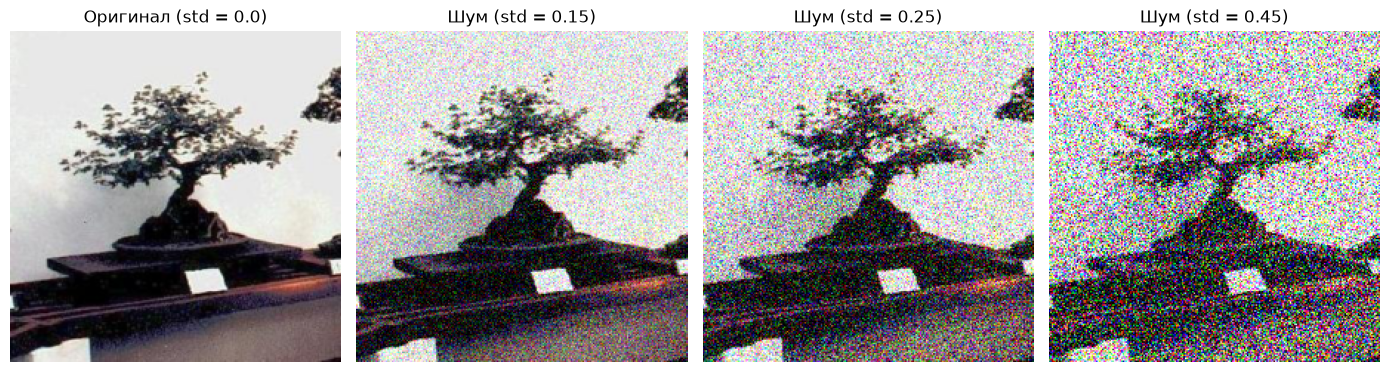

In [47]:
clean_tensor = dataset[0][0]

stds = [0.0, 0.15, 0.25, 0.45]
fig, axes = plt.subplots(1, len(stds), figsize=(14, 4))

for ax, s in zip(axes, stds):
    if s == 0.0:
        img = clean_tensor
        title = "Оригинал (std = 0.0)"
    else:
        img = torch.clamp(clean_tensor + torch.randn_like(clean_tensor) * s, 0.0, 1.0)
        title = f"Шум (std = {s})"
        
    ax.imshow(img.permute(1, 2, 0).numpy())
    ax.set_title(title)
    ax.axis('off')

plt.tight_layout()
plt.show()

In [48]:
model = MyConvNet(num_channels=3, num_classes=2, num_kernels = 64)
results = train_one_model(
    model=model,
    train_loader=train_loader_noisy,
    val_loader=test_loader_noisy,
)

Epoch [1/50] | train_loss: 0.6763, train_acc: 0.6623 | val_loss: 0.7210, val_acc: 0.6053 | lr: 0.001000


Epoch [2/50] | train_loss: 0.6310, train_acc: 0.6818 | val_loss: 0.6546, val_acc: 0.6053 | lr: 0.001000


Epoch [3/50] | train_loss: 0.6279, train_acc: 0.6818 | val_loss: 0.6482, val_acc: 0.6053 | lr: 0.001000


Epoch [4/50] | train_loss: 0.6064, train_acc: 0.6818 | val_loss: 0.6298, val_acc: 0.6053 | lr: 0.001000


Epoch [5/50] | train_loss: 0.5663, train_acc: 0.6818 | val_loss: 0.5820, val_acc: 0.6053 | lr: 0.001000


Epoch [6/50] | train_loss: 0.5172, train_acc: 0.7338 | val_loss: 0.3975, val_acc: 0.8684 | lr: 0.001000


... (4 outputs left out)

Epoch [11/50] | train_loss: 0.3993, train_acc: 0.8571 | val_loss: 0.4776, val_acc: 0.8684 | lr: 0.001000


Epoch [12/50] | train_loss: 0.2243, train_acc: 0.8896 | val_loss: 0.3956, val_acc: 0.8421 | lr: 0.001000


Epoch [13/50] | train_loss: 0.2020, train_acc: 0.8896 | val_loss: 0.6184, val_acc: 0.8684 | lr: 0.000100


Epoch [14/50] | train_loss: 0.2814, train_acc: 0.8896 | val_loss: 0.5943, val_acc: 0.9211 | lr: 0.000100
Early stopping worked on 14


In [50]:
model = MyConvNet(num_channels=3, num_classes=2, num_kernels = 8)
results = train_one_model(
    model=model,
    train_loader=train_loader_noisy,
    val_loader=test_loader_noisy,
)

Epoch [1/50] | train_loss: 0.6585, train_acc: 0.6299 | val_loss: 0.6874, val_acc: 0.6053 | lr: 0.001000


Epoch [2/50] | train_loss: 0.6297, train_acc: 0.6818 | val_loss: 0.6688, val_acc: 0.6053 | lr: 0.001000


Epoch [3/50] | train_loss: 0.6181, train_acc: 0.6818 | val_loss: 0.6555, val_acc: 0.6053 | lr: 0.001000


Epoch [4/50] | train_loss: 0.6188, train_acc: 0.6818 | val_loss: 0.6550, val_acc: 0.6053 | lr: 0.001000


Epoch [5/50] | train_loss: 0.6075, train_acc: 0.6818 | val_loss: 0.6730, val_acc: 0.6053 | lr: 0.001000


Epoch [6/50] | train_loss: 0.6172, train_acc: 0.6818 | val_loss: 0.6792, val_acc: 0.6053 | lr: 0.001000


... (18 outputs left out)

Epoch [25/50] | train_loss: 0.5416, train_acc: 0.7403 | val_loss: 0.8419, val_acc: 0.6842 | lr: 0.001000


Epoch [26/50] | train_loss: 0.3467, train_acc: 0.8117 | val_loss: 0.4589, val_acc: 0.7632 | lr: 0.001000


Epoch [27/50] | train_loss: 0.2743, train_acc: 0.9091 | val_loss: 0.4747, val_acc: 0.7895 | lr: 0.000100


Epoch [28/50] | train_loss: 0.2340, train_acc: 0.8896 | val_loss: 0.4464, val_acc: 0.7895 | lr: 0.000100
Early stopping worked on 28


Точность значительно падает, но время сходимости уменьшается. Видимо градиенты гораздо быстрее падают минимум за счет случайного попадания.

# Контрольные вопросы
1. Как рассчитывается число элементов на каждом свёрточном слое?

$$N = C_{\text{out}} \times H_{\text{out}} \times W_{\text{out}}$$

где высота $H_{\text{out}}$ и ширина $W_{\text{out}}$ зависят от размера входной карты ($H_{\text{in}}, W_{\text{in}}$), размера ядра ($K$), отступа (padding, $P$) и шага (stride, $S$):$$H_{\text{out}} = \left\lfloor \frac{H_{\text{in}} + 2P - K}{S} \right\rfloor + 1, \quad W_{\text{out}} = \left\lfloor \frac{W_{\text{in}} + 2P - K}{S} \right\rfloor + 1$$

2. Зачем данные после свёртки часто обобщают посредством MaxPool или другой процедуры
обработки?

Пулинг сжимает карту признаков. Это снижает число параметров, снижая риск переобучения. Также макспул содержит информацию о окрестности точки. Если объект сдвинется на пару пикселй - максимум останется тем же.

3. Каковы преимущества у остаточных сетей по сравнению с классическими свёрточными?

Благодаря пробросам входных данных в выход при бекпропе градиент проходит напрямую через тождественные связи без многократного умножения на малые производные, что позволяет обучать глубокие сети. Если какой-то блок становится ненужным, то сеть его обнулит и пропустит входной сигнал. Это в каком-то смысле более простая реализация тождественного преобразования. Также проброс означает сохранение прямого доступа верхних слоев к низкоуровневым признакам с ранних слоев. Поэтому сеть быстрее сходится и требует меньше эпох для выхода на плато